In [21]:
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [22]:
df=pd.read_csv("customers.csv")
df

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...,...
10690,467954,Male,No,29,No,Healthcare,9.0,Low,4.0,Cat_6,B
10691,467958,Female,No,35,Yes,Doctor,1.0,Low,1.0,Cat_6,A
10692,467960,Female,No,53,Yes,Entertainment,NaN,Low,2.0,Cat_6,C
10693,467961,Male,Yes,47,Yes,Executive,1.0,High,5.0,Cat_4,C


In [23]:
df.shape

(10695, 11)

In [24]:
df=df.drop(columns="ID")

In [25]:
df.fillna({"Work_Experience":0,"Family_Size":df["Family_Size"].median()},inplace=True)
df

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,Female,Yes,38,Yes,Engineer,0.0,Average,3.0,Cat_4,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,Female,Yes,40,Yes,Entertainment,0.0,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...
10690,Male,No,29,No,Healthcare,9.0,Low,4.0,Cat_6,B
10691,Female,No,35,Yes,Doctor,1.0,Low,1.0,Cat_6,A
10692,Female,No,53,Yes,Entertainment,0.0,Low,2.0,Cat_6,C
10693,Male,Yes,47,Yes,Executive,1.0,High,5.0,Cat_4,C


In [26]:
cat_cols=["Gender","Ever_Married","Graduated","Profession","Spending_Score","Var_1"]
for col in cat_cols:
    df[col]=LabelEncoder().fit_transform(df[col])
df

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,1,0,22,0,5,1.0,2,4.0,3,D
1,0,1,38,1,2,0.0,0,3.0,3,A
2,0,1,67,1,2,1.0,2,1.0,5,B
3,1,1,67,1,7,0.0,1,2.0,5,B
4,0,1,40,1,3,0.0,1,6.0,5,A
...,...,...,...,...,...,...,...,...,...,...
10690,1,0,29,0,5,9.0,2,4.0,5,B
10691,0,0,35,1,1,1.0,2,1.0,5,A
10692,0,0,53,1,3,0.0,2,2.0,5,C
10693,1,1,47,1,4,1.0,1,5.0,3,C


In [27]:
encoder = LabelEncoder()
x=df.drop(columns="Segmentation")
y = encoder.fit_transform(df["Segmentation"])
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [28]:
scaler1=StandardScaler()
scaler2=StandardScaler()
x_train=scaler1.fit_transform(x_train)
x_test=scaler2.fit_transform(x_test)

In [29]:
x_train=torch.FloatTensor(x_train)
x_test=torch.FloatTensor(x_test)
y_train=torch.FloatTensor(y_train)
y_test=torch.FloatTensor(y_test)

In [30]:
train_dataset=TensorDataset(x_train,y_train)
test_dataset=TensorDataset(x_test,y_test)
train_loader=DataLoader(train_dataset,batch_size=16,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=16)

In [31]:
class classification_model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.l1=nn.Linear(input_size,32)
        self.l2=nn.Linear(32,16)
        self.l3=nn.Linear(16,8)
        self.l4=nn.Linear(8,4)
        
    def forward(self,x):
        x=torch.relu(self.l1(x))
        x=torch.relu(self.l2(x))
        x=torch.relu(self.l3(x))
        x=self.l4(x)
        return x

In [32]:
input_size=x_train.shape[1]
model=classification_model(input_size)
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

In [33]:
epochs=200
for i in range(epochs):
    for a,b in train_loader:
        optimizer.zero_grad()
        pred=model(a)
        loss=criterion(pred,b.long())
        loss.backward()
        optimizer.step()

    if i%20==0:
        print(f"Epoch {i}/{epochs}, Loss: {loss.item():.4f}")

Epoch 0/200, Loss: 0.9441
Epoch 20/200, Loss: 1.0498
Epoch 40/200, Loss: 0.9317
Epoch 60/200, Loss: 0.9576
Epoch 80/200, Loss: 0.9399
Epoch 100/200, Loss: 1.1454
Epoch 120/200, Loss: 1.0773
Epoch 140/200, Loss: 0.9606
Epoch 160/200, Loss: 0.9672
Epoch 180/200, Loss: 0.8208


In [34]:
model.eval()

with torch.no_grad():
    outputs = model(x_test.float())
    pred = torch.argmax(outputs, dim=1)
    loss = criterion(outputs, y_test.long().view(-1))
    print("Test Loss:", loss.item())

Test Loss: 1.2251828908920288


DEVELOPED BY SUJIN M L 
REGISTER NUMBER : 212225040435
Accuracy Score : 0.46143057503506313
Classification Report :
               precision    recall  f1-score   support

           A       0.39      0.30      0.33       584
           B       0.37      0.35      0.36       490
           C       0.48      0.51      0.50       472
           D       0.55      0.68      0.61       593

    accuracy                           0.46      2139
   macro avg       0.45      0.46      0.45      2139
weighted avg       0.45      0.46      0.45      2139

Confusion Matrix :
 [[173 148  90 173]
 [ 99 170 128  93]
 [ 69 103 242  58]
 [108  42  41 402]]


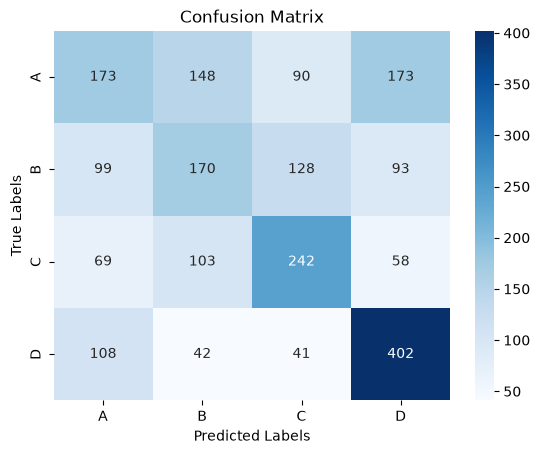

In [35]:
accuracy = accuracy_score(y_test, pred)
conf_matrix = confusion_matrix(y_test, pred)
class_report = classification_report(y_test, pred, target_names=['A','B','C','D'])
conf_matrix = confusion_matrix(y_test,pred)
print("DEVELOPED BY SUJIN M L ")
print("REGISTER NUMBER : 212225040435")
print("Accuracy Score :",accuracy)
print("Classification Report :\n",class_report)
print("Confusion Matrix :\n",conf_matrix)
sns.heatmap(conf_matrix, annot=True, cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_,fmt='g')
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()